In [42]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url) 

df.head()




,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


#### Data Preparation

In [43]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [44]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [45]:
categorical = ['lead_source', 'industry', 'employment_status', 'location'] 
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [46]:
df[numerical] = df[numerical].fillna(0.0) 
df[categorical] = df[categorical].fillna('NA')

In [47]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [48]:
from sklearn.model_selection import train_test_split

In [49]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
) 

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [50]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [51]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = model.predict_proba(X_val)[:, 1]
converted_decision = (y_pred >= 0.5)

### Question 1: ROC AUC feature importance

In [52]:
from sklearn.metrics import roc_auc_score

In [53]:
for v in numerical:
    auc = roc_auc_score(y_train, df_train[v])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[v])
    print(f'{v:28s} {auc:.3f}')

annual_income                0.608
number_of_courses_viewed     0.723
interaction_count            0.765
lead_score                   0.788


### Question 2: Training the model

In [54]:
roc_auc_score(y_val, y_pred)

0.7318222288173319

### Question 3: Precision and Recall

In [55]:
thresholds = np.linspace(0.0, 1.0, 101)  

scores = []  

actual_positive = (y_val == 1) 
actual_negative = (y_val == 0) 

for t in thresholds: 
    predict_positive = (y_pred >= t) 
    predict_negative = (y_pred < t) 

    tp = (predict_positive & actual_positive).sum() 
    tn = (predict_negative & actual_negative).sum() 
    fp = (predict_positive & actual_negative).sum() 
    fn = (predict_negative & actual_positive).sum() 

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) 

    scores.append((t, precision, recall)) 

df_pr = pd.DataFrame(scores, columns =['threshold', 'precision', 'recall'])

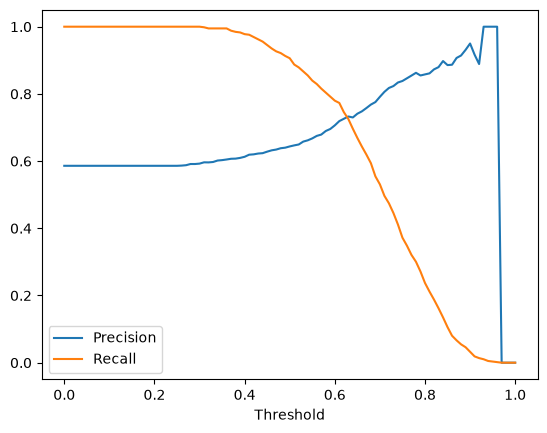

In [56]:
plt.plot(df_pr.threshold, df_pr.precision, label='Precision')
plt.plot(df_pr.threshold, df_pr.recall, label='Recall')
plt.xlabel('Threshold')
plt.legend()

In [57]:
df_pr['diff'] = (df_pr.precision - df_pr.recall).abs()
df_pr[(df_pr.precision > 0) | (df_pr.recall > 0)].sort_values('diff').head()

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


### Question 4: F1 score

In [62]:
thresholds = np.linspace(0.0, 1.0, 101)  

scores = []  

actual_positive = (y_val == 1) 
actual_negative = (y_val == 0) 

for t in thresholds: 
    predict_positive = (y_pred >= t) 
    predict_negative = (y_pred < t) 

    tp = (predict_positive & actual_positive).sum() 
    tn = (predict_negative & actual_negative).sum() 
    fp = (predict_positive & actual_negative).sum() 
    fn = (predict_negative & actual_positive).sum() 

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn)  
    f1 = 2*(precision*recall) / (precision+recall) if (precision + recall) > 0 else 0

    scores.append((t, f1)) 
df_f1 = pd.DataFrame(scores, columns =['threshold', 'f1']) 
df_f1.sort_values('f1', ascending=False).head()

,threshold,f1
41,0.41,0.757616
42,0.42,0.756325
43,0.43,0.756032
45,0.45,0.754768
44,0.44,0.754717


Text(0, 0.5, 'F1')

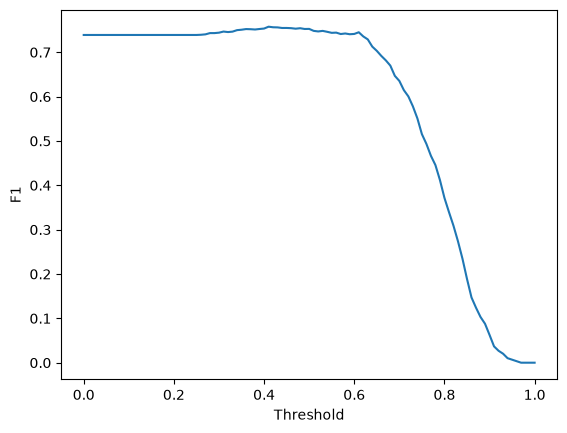

In [63]:
plt.plot(df_f1.threshold, df_f1.f1)
plt.xlabel('Threshold')
plt.ylabel('F1')

### Question 5: 5-Fold CV

In [64]:
def train(df_train, y_train, C=1.0): 
    dicts = df_train[categorical + numerical].to_dict(orient='records') 

    dv = DictVectorizer(sparse=False) 
    X_train = dv.fit_transform(dicts) 

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000) 
    model.fit(X_train, y_train) 

    return dv, model

In [65]:
def predict(df, dv, model): 
    dicts = df[categorical + numerical].to_dict(orient='records') 

    X = dv.transform(dicts) 
    y_pred = model.predict_proba(X)[:, 1] 

    return y_pred

In [66]:
from sklearn.model_selection import KFold

In [70]:
from tqdm.auto import tqdm

In [74]:
scores = [] 
n_splits = 5
kfold = KFold(n_splits=5, shuffle=True, random_state=1) 

for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=n_splits):

        df_train = df_full_train.iloc[train_idx] 
        df_val = df_full_train.iloc[val_idx]  

        y_train = df_train.converted.values 
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=1.0) 
        y_pred = predict(df_val, dv, model) 

        auc = roc_auc_score(y_val, y_pred) 
        scores.append(auc) 

        print(' %.3f +- %.3f' % (np.mean(scores), np.std(scores)))

  0%|          | 0/5 [00:00<?, ?it/s]

 0.731 +- 0.000
 0.730 +- 0.000
 0.732 +- 0.003
 0.734 +- 0.005
 0.732 +- 0.007


### Question 6: Hyperparameter Tuning

In [76]:
for C in [ 0.000001, 0.001, 1 ]: 
    scores = [] 
    n_splits = 5

    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1) 

    for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=n_splits):

        df_train = df_full_train.iloc[train_idx] 
        df_val = df_full_train.iloc[val_idx]  

        y_train = df_train.converted.values 
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C) 
        y_pred = predict(df_val, dv, model) 

        auc = roc_auc_score(y_val, y_pred) 
        scores.append(auc) 

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/5 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019


  0%|          | 0/5 [00:00<?, ?it/s]

C=0.001 0.749 +- 0.010


  0%|          | 0/5 [00:00<?, ?it/s]

C=1 0.732 +- 0.007
